<a href="https://colab.research.google.com/github/ZackyRioOrlando/Praktikum-Pembelajaran-Mesin-/blob/main/JS09/JS09_Tugas_Lab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

🥎
Tugas Lab 2

Lakukan percobaan penggunaan ANNOY, FAISS, dan HNSWLIB pada dataset sekunder berukuran besar (Micro Spotify) pada link berikut: https://www.kaggle.com/datasets/bwandowando/spotify-songs-with-attributes-and-lyrics/data .

- Download data dan load CSV filenya (pilih dataset yg pertama dari dua dataset).

- Pilih hanya fitur numerik saja, dan lakukan normalisasi menggunakan StandardScaler.

- Lakukan pencarian track terdekat dan bandingkan hasilnya.

- Lakkan perbandingan pada exact NN, ANNOY, FAISS, dan HNSW

Langkah 1 - Hubungkan Google Drive ke Colab

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Langkah 2 – Membaca Dataset

In [6]:
path = '/content/drive/MyDrive/Machine Learning/songs_with_attributes_and_lyrics.csv'

df = pd.read_csv(path, nrows=5)

print("Dataset berhasil dibaca!")

Dataset berhasil dibaca!


Langkah 3 – Import Library dan Load Dataset

In [3]:
!pip install annoy faiss-cpu hnswlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 6.5 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 10.2 MB/s  0:00:01
  Created wheel for annoy: filename=annoy-1.17.3-cp313-cp313-linux_x86_64.whl size=520034 sha256=8a10df1daa14204e1ee2cd1dd4257f2e469992610c88338705e7da3b4f6a50b5
  Stored in directory: /root/.cache/pip/wheels/fc/4e/87/f1f957e7382aa370452cff98276f51686924d5415e449800ed
  Created wheel for hnswlib: filename=hnswlib-0.8.0-cp313-cp313-linux_x86_64.whl size=2679802 sha256=b622889448d56fd21ba0ab7cdd0b45557f96d044cc1502cf7e3c77accb60eaf3
  Stored in directory: /root/.cache/pip/wheels/35/04/88/b31765a4b9957705e18065db4657e61fc8da54f50

In [18]:

import pandas as pd
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# -------------------------------
# Load dataset
# -------------------------------
path = '/content/drive/MyDrive/Machine Learning/songs_with_attributes_and_lyrics.csv'

df = pd.read_csv(path)

features = [
    'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness',
    'valence', 'tempo'
]

X = df[features].apply(pd.to_numeric, errors='coerce')

# Membersihkan data kosong dan tak hingga
X = X.replace([np.inf, -np.inf], np.nan)
mask = X.notna().all(axis=1)

X = X.loc[mask]
df = df.loc[mask].reset_index(drop=True)

# Mengubah data menjadi float32
X = X.values.astype(np.float32)

# -------------------------------
# Standarisasi fitur
# -------------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X).astype(np.float32)

k = 10  # jumlah nearest neighbors

print("Dataset berhasil dimuat!")
print("Jumlah data:", X_scaled.shape[0])
print("Jumlah fitur:", X_scaled.shape[1])

Dataset berhasil dimuat!
Jumlah data: 955320
Jumlah fitur: 9


Langkah 4 – Melihat Informasi Dataset

In [19]:
# Melihat informasi dataset
print("Ukuran dataset:", df.shape)

print("\nInformasi dataset:")
df.info()

print("\nLima data pertama:")
display(df.head())

print("\nStatistik deskriptif:")
display(df[features].describe())

Ukuran dataset: (955320, 17)

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 955320 entries, 0 to 955319
Data columns (total 17 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   id                955320 non-null  object 
 1   name              955309 non-null  object 
 2   album_name        385557 non-null  object 
 3   artists           955315 non-null  object 
 4   danceability      955320 non-null  float64
 5   energy            955320 non-null  float64
 6   key               955320 non-null  object 
 7   loudness          955320 non-null  float64
 8   mode              955320 non-null  object 
 9   speechiness       955320 non-null  float64
 10  acousticness      955320 non-null  float64
 11  instrumentalness  955320 non-null  float64
 12  liveness          955320 non-null  float64
 13  valence           955320 non-null  float64
 14  tempo             955320 non-null  float64
 15  duration_ms       9

,id,name,album_name,artists,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,lyrics
0,0Prct5TDjAnEgIqbxcldY9,!,UNDEN!ABLE,HELLYEAH,0.415,0.6050,7,-11.157,1,0.0575,0.00116,0.838000,0.4710,0.193,100.059,79500.0,"He said he came from Jamaica,\n he owned a cou..."
1,2ASl4wirkeYm3OWZxXKYuq,!!,NaN,Yxngxr1,0.788,0.6480,7,-9.135,0,0.3150,0.90000,0.000000,0.1760,0.287,79.998,114000.0,"Fucked a bitch, now she running with my kids\n..."
2,69lcggVPmOr9cvPx9kLiiN,!!! - Interlude,Where I Belong EP,Glowie,0.000,0.0354,7,-20.151,0,0.0000,0.90800,0.000000,0.4790,0.000,0.000,11413.0,"Oh, my God, I'm going crazy\n"
3,4U7dlZjg1s9pjdppqZy0fm,!!De Repente!!,Un Palo Al Agua (20 Grandes Canciones),Rosendo,0.657,0.8820,5,-6.340,1,0.0385,0.00740,0.000013,0.0474,0.939,123.588,198173.0,Continuamente se extraña la gente si no puede ...
4,4v1IBp3Y3rpkWmWzIlkYju,!!De Repente!!,Fuera De Lugar,Rosendo,0.659,0.8930,5,-8.531,1,0.0411,0.09220,0.000019,0.0534,0.951,123.600,199827.0,Continuamente se extraña la gente si no puede ...



Statistik deskriptif:


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
count,955320.000000,955320.000000,955320.000000,955320.000000,955320.000000,955320.000000,955320.000000,955320.000000,955320.000000
mean,0.550710,0.652442,-7.833732,0.083638,0.282962,0.081875,0.220190,0.488119,122.226093
std,0.169784,0.238824,3.792018,0.092929,0.311800,0.212789,0.195938,0.251468,29.536303
min,0.000000,0.000000,-60.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.436000,0.482000,-9.750000,0.034500,0.011900,0.000000,0.098900,0.282000,99.021000
50%,0.558000,0.687000,-7.041000,0.047800,0.142000,0.000039,0.137000,0.477000,120.661000
75%,0.675000,0.857000,-5.148000,0.087625,0.518000,0.008660,0.285000,0.690000,140.094000
max,0.993000,1.000000,4.882000,0.966000,0.996000,1.000000,1.000000,1.000000,246.130000


Langkah 5 – Menentukan Data Pengujian

In [20]:
# Mengubah data menjadi float32
X_scaled = X_scaled.astype(np.float32)

# Menentukan jumlah data query
jumlah_query = 20

# Memilih query secara acak
np.random.seed(42)

query_index = np.random.choice(
    len(X_scaled),
    jumlah_query,
    replace=False
)

Q = X_scaled[query_index]

print("Jumlah data:", len(X_scaled))
print("Jumlah query:", len(Q))
print("Dimensi fitur:", X_scaled.shape[1])

Jumlah data: 955320
Jumlah query: 20
Dimensi fitur: 9


Langkah 6 – Pengujian Exact NN

In [21]:
# Membuat model Exact Nearest Neighbor
exact_nn = NearestNeighbors(
    n_neighbors=k + 1,
    metric='euclidean',
    algorithm='brute'
)

# Mengukur waktu pembangunan model
start = time.time()
exact_nn.fit(X_scaled)
build_exact = time.time() - start

# Mengukur waktu pencarian
start = time.time()
exact_distances, exact_indices = exact_nn.kneighbors(Q)
query_exact = (time.time() - start) / jumlah_query

print("Exact NN Build Time:", round(build_exact, 4), "detik")
print("Exact NN Query Time:", round(query_exact * 1000, 4), "ms")

print("\nTetangga terdekat:")
print(exact_indices[0])

Exact NN Build Time: 0.0971 detik
Exact NN Query Time: 20.1667 ms

Tetangga terdekat:
[174137  97012 645522  97011 869738 851758 413158 246126 417023 807751
 483137]


Langkah 7 – Pengujian ANNOY

In [22]:
# Membuat index ANNOY
dim = X_scaled.shape[1]

ann_index = AnnoyIndex(dim, 'euclidean')

start = time.time()

for i in range(len(X_scaled)):
    ann_index.add_item(i, X_scaled[i])

ann_index.build(10)

build_annoy = time.time() - start

# Pencarian tetangga terdekat
start = time.time()

ann_results = []

for q in Q:
    neighbors = ann_index.get_nns_by_vector(q, k + 1)
    ann_results.append(neighbors)

query_annoy = (time.time() - start) / jumlah_query

print("ANNOY Build Time:", round(build_annoy, 4), "detik")
print("ANNOY Query Time:", round(query_annoy * 1000, 4), "ms")

print("\nTetangga terdekat:")
print(ann_results[0])

ANNOY Build Time: 22.5817 detik
ANNOY Query Time: 0.0855 ms

Tetangga terdekat:
[174137, 97012, 645522, 97011, 869738, 413158, 246126, 417023, 483137, 655241, 822181]


Langkah 8 – Pengujian FAISS

In [23]:
# Membuat index FAISS
dim = X_scaled.shape[1]
n_data = len(X_scaled)

nlist = min(100, max(10, int(np.sqrt(n_data))))

quantizer = faiss.IndexFlatL2(dim)

faiss_index = faiss.IndexIVFFlat(
    quantizer,
    dim,
    nlist,
    faiss.METRIC_L2
)

start = time.time()

# Melatih index
faiss_index.train(X_scaled)

# Memasukkan data
faiss_index.add(X_scaled)

build_faiss = time.time() - start

# Mengatur jumlah cluster yang diperiksa
faiss_index.nprobe = min(10, nlist)

# Pencarian tetangga terdekat
start = time.time()

faiss_distances, faiss_indices = faiss_index.search(Q, k + 1)

query_faiss = (time.time() - start) / jumlah_query

print("FAISS Build Time:", round(build_faiss, 4), "detik")
print("FAISS Query Time:", round(query_faiss * 1000, 4), "ms")

print("\nTetangga terdekat:")
print(faiss_indices[0])

FAISS Build Time: 0.3557 detik
FAISS Query Time: 0.9482 ms

Tetangga terdekat:
[174137  97012 645522  97011 869738 851758 413158 246126 417023 807751
 483137]


Langkah 9 – Pengujian HNSW

In [24]:
# Membuat index HNSW
dim = X_scaled.shape[1]

hnsw_index = hnswlib.Index(
    space='l2',
    dim=dim
)

start = time.time()

hnsw_index.init_index(
    max_elements=len(X_scaled),
    ef_construction=200,
    M=16
)

hnsw_index.add_items(X_scaled)

build_hnsw = time.time() - start

# Mengatur parameter pencarian
hnsw_index.set_ef(50)

# Pencarian tetangga terdekat
start = time.time()

hnsw_labels, hnsw_distances = hnsw_index.knn_query(Q, k=k + 1)

query_hnsw = (time.time() - start) / jumlah_query

print("HNSW Build Time:", round(build_hnsw, 4), "detik")
print("HNSW Query Time:", round(query_hnsw * 1000, 4), "ms")

print("\nTetangga terdekat:")
print(hnsw_labels[0])

HNSW Build Time: 242.7013 detik
HNSW Query Time: 0.1021 ms

Tetangga terdekat:
[174137  97012 645522  97011 869738 851758 413158 246126 417023 807751
 483137]


Langkah 10 – Menampilkan Track Terdekat

In [25]:
# Menghapus lagu query dari hasil pencarian
def hapus_query_sendiri(hasil_prediksi, query_index):

    hasil_baru = []

    for query_id, neighbors in zip(query_index, hasil_prediksi):

        neighbors = [
            int(i) for i in neighbors
            if int(i) != int(query_id)
        ]

        hasil_baru.append(neighbors[:k])

    return hasil_baru


# Membersihkan hasil pencarian
exact_indices = hapus_query_sendiri(
    exact_indices, query_index
)

ann_results = hapus_query_sendiri(
    ann_results, query_index
)

faiss_indices = hapus_query_sendiri(
    faiss_indices, query_index
)

hnsw_labels = hapus_query_sendiri(
    hnsw_labels, query_index
)


# Menampilkan lagu yang dicari
query_id = int(query_index[0])

print("LAGU YANG DICARI:")
display(
    df.iloc[[query_id]][
        ['name', 'artists', 'album_name']
    ]
)


# Menggabungkan hasil algoritma
algoritma = {
    'Exact NN': exact_indices,
    'ANNOY': ann_results,
    'FAISS': faiss_indices,
    'HNSW': hnsw_labels
}


# Menampilkan rekomendasi lagu
for nama, hasil_prediksi in algoritma.items():

    print("\nHasil pencarian:", nama)

    indeks = hasil_prediksi[0]

    rekomendasi = df.iloc[indeks][
        ['name', 'artists', 'album_name']
    ].copy()

    rekomendasi.insert(0, 'Index', indeks)

    display(rekomendasi)

LAGU YANG DICARI:


,name,artists,album_name
174137,Dans La Nuit,Sarah Brightman,NaN



Hasil pencarian: Exact NN


,Index,name,artists,album_name
97012,97012,Blue (with Sarah Vaughan),"Barry Manilow, Sarah Vaughan",2:00 A.M. Paradise Cafè
645522,645522,Revolutions,Nobuo Uematsu,NaN
97011,97011,Blue (with Sarah Vaughan),"Barry Manilow, Sarah Vaughan",Duets
869738,869738,We Have All The Time In The World,Alfie Boe,NaN
851758,851758,"Vesti la giubba (From ""For the First Time"")",Mario Lanza,NaN
413158,413158,Jupiter 4,Marika Hackman,Covers
246126,246126,Exsultate,Libera,NaN
417023,417023,Kahit Konting Pagtingin,Sharon Cuneta,The Best Of Sharon Cuneta
807751,807751,This One's From The Heart,"Tom Waits, Crystal Gayle","Music From The Original Motion Picture ""One Fr..."
483137,483137,MORNING PRAYER,Minako Yoshida,LIGHT'N UP



Hasil pencarian: ANNOY


,Index,name,artists,album_name
97012,97012,Blue (with Sarah Vaughan),"Barry Manilow, Sarah Vaughan",2:00 A.M. Paradise Cafè
645522,645522,Revolutions,Nobuo Uematsu,NaN
97011,97011,Blue (with Sarah Vaughan),"Barry Manilow, Sarah Vaughan",Duets
869738,869738,We Have All The Time In The World,Alfie Boe,NaN
413158,413158,Jupiter 4,Marika Hackman,Covers
246126,246126,Exsultate,Libera,NaN
417023,417023,Kahit Konting Pagtingin,Sharon Cuneta,The Best Of Sharon Cuneta
483137,483137,MORNING PRAYER,Minako Yoshida,LIGHT'N UP
655241,655241,Roses Blue,Joni Mitchell,NaN
822181,822181,"Tosca (2002 Digital Remaster), Act II: Tosca, ...",Maria Callas,NaN



Hasil pencarian: FAISS


,Index,name,artists,album_name
97012,97012,Blue (with Sarah Vaughan),"Barry Manilow, Sarah Vaughan",2:00 A.M. Paradise Cafè
645522,645522,Revolutions,Nobuo Uematsu,NaN
97011,97011,Blue (with Sarah Vaughan),"Barry Manilow, Sarah Vaughan",Duets
869738,869738,We Have All The Time In The World,Alfie Boe,NaN
851758,851758,"Vesti la giubba (From ""For the First Time"")",Mario Lanza,NaN
413158,413158,Jupiter 4,Marika Hackman,Covers
246126,246126,Exsultate,Libera,NaN
417023,417023,Kahit Konting Pagtingin,Sharon Cuneta,The Best Of Sharon Cuneta
807751,807751,This One's From The Heart,"Tom Waits, Crystal Gayle","Music From The Original Motion Picture ""One Fr..."
483137,483137,MORNING PRAYER,Minako Yoshida,LIGHT'N UP



Hasil pencarian: HNSW


,Index,name,artists,album_name
97012,97012,Blue (with Sarah Vaughan),"Barry Manilow, Sarah Vaughan",2:00 A.M. Paradise Cafè
645522,645522,Revolutions,Nobuo Uematsu,NaN
97011,97011,Blue (with Sarah Vaughan),"Barry Manilow, Sarah Vaughan",Duets
869738,869738,We Have All The Time In The World,Alfie Boe,NaN
851758,851758,"Vesti la giubba (From ""For the First Time"")",Mario Lanza,NaN
413158,413158,Jupiter 4,Marika Hackman,Covers
246126,246126,Exsultate,Libera,NaN
417023,417023,Kahit Konting Pagtingin,Sharon Cuneta,The Best Of Sharon Cuneta
807751,807751,This One's From The Heart,"Tom Waits, Crystal Gayle","Music From The Original Motion Picture ""One Fr..."
483137,483137,MORNING PRAYER,Minako Yoshida,LIGHT'N UP


Langkah 11 – Perbandingan Hasil

In [26]:
# Menghitung Recall@10
def hitung_recall(hasil_prediksi, hasil_exact):

    total_recall = 0

    for prediksi, exact in zip(hasil_prediksi, hasil_exact):

        jumlah_sama = len(set(prediksi) & set(exact))

        total_recall += jumlah_sama / k

    return total_recall / len(hasil_exact)


# Menghitung recall setiap algoritma
recall_annoy = hitung_recall(
    ann_results, exact_indices
)

recall_faiss = hitung_recall(
    faiss_indices, exact_indices
)

recall_hnsw = hitung_recall(
    hnsw_labels, exact_indices
)


# Membuat tabel perbandingan
hasil = pd.DataFrame({

    'Algoritma': [
        'Exact NN',
        'ANNOY',
        'FAISS',
        'HNSW'
    ],

    'Build Time (detik)': [
        build_exact,
        build_annoy,
        build_faiss,
        build_hnsw
    ],

    'Query Time (ms)': [
        query_exact * 1000,
        query_annoy * 1000,
        query_faiss * 1000,
        query_hnsw * 1000
    ],

    'Recall@10': [
        1.0,
        recall_annoy,
        recall_faiss,
        recall_hnsw
    ]

})

print("TABEL PERBANDINGAN HASIL")
display(hasil.round(4))

TABEL PERBANDINGAN HASIL


,Algoritma,Build Time (detik),Query Time (ms),Recall@10
0,Exact NN,0.0971,20.1667,1.0
1,ANNOY,22.5817,0.0855,0.8
2,FAISS,0.3557,0.9482,1.0
3,HNSW,242.7013,0.1021,1.0


Langkah 12 – Grafik Perbandingan

A. Grafik Query Time

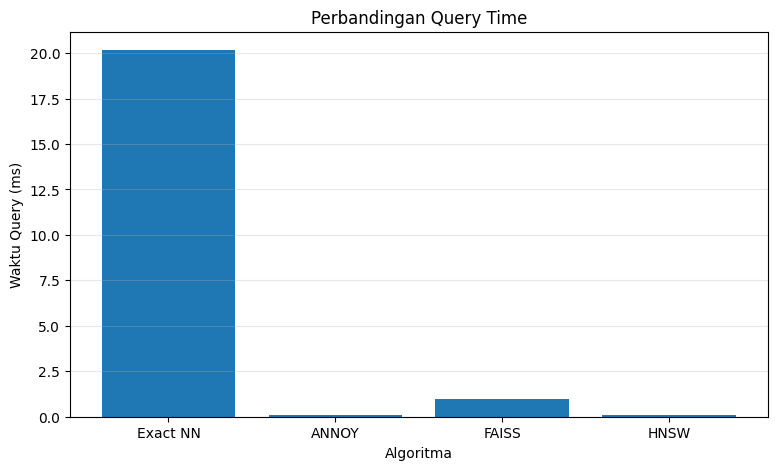

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    hasil['Algoritma'],
    hasil['Query Time (ms)']
)

plt.title('Perbandingan Query Time')
plt.xlabel('Algoritma')
plt.ylabel('Waktu Query (ms)')
plt.grid(axis='y', alpha=0.3)

plt.show()

B. Grafik Build Time

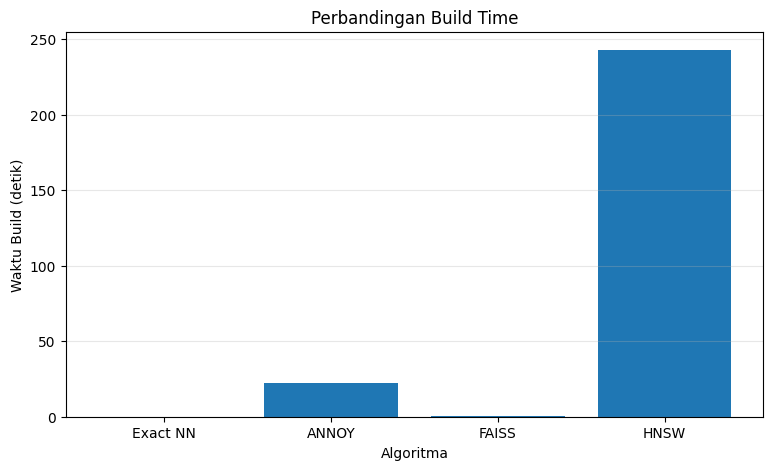

In [28]:
plt.figure(figsize=(9, 5))

plt.bar(
    hasil['Algoritma'],
    hasil['Build Time (detik)']
)

plt.title('Perbandingan Build Time')
plt.xlabel('Algoritma')
plt.ylabel('Waktu Build (detik)')
plt.grid(axis='y', alpha=0.3)

plt.show()

C. Grafik Recall@10

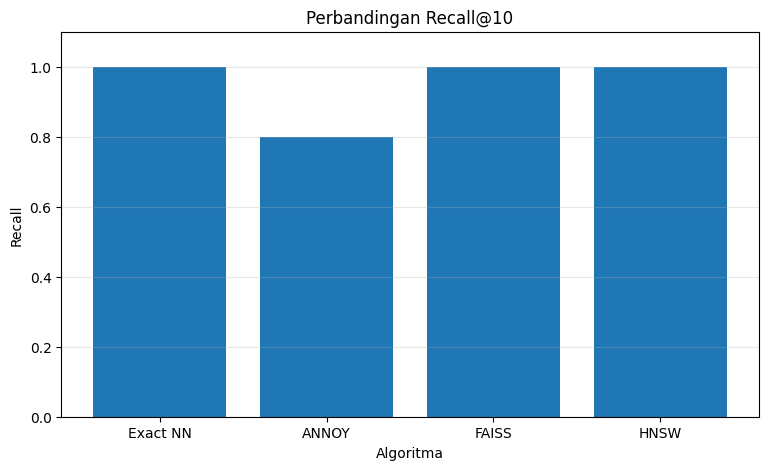

In [29]:
plt.figure(figsize=(9, 5))

plt.bar(
    hasil['Algoritma'],
    hasil['Recall@10']
)

plt.title('Perbandingan Recall@10')
plt.xlabel('Algoritma')
plt.ylabel('Recall')
plt.ylim(0, 1.1)
plt.grid(axis='y', alpha=0.3)

plt.show()